In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

plt.style.use('seaborn-v0_8-whitegrid')
os.makedirs('../visuals', exist_ok=True)

df = pd.read_parquet('../data/processed/yellow_tripdata_2024-01_engineered.parquet')
print(f"Loaded: {len(df):,} rows")

Loaded: 2,338,354 rows


In [2]:
print("=" * 55)
print("  OVERALL STATISTICS")
print("=" * 55)
print(f"Total Trips:        {len(df):,}")
print(f"Total Passengers:   {df['passenger_count'].sum():,.0f}")
print(f"Avg Trip Distance:  {df['trip_distance'].mean():.2f} miles")
print(f"Avg Trip Duration:  {df['trip_duration_min'].mean():.1f} minutes")
print(f"Avg Speed:          {df['avg_speed_mph'].mean():.1f} mph")
print(f"Avg Fare:           ${df['fare_amount'].mean():.2f}")
print(f"Avg Fare/Mile:      ${df['fare_per_mile'].mean():.2f}")
print(f"Congestion Rate:    {df['is_congested_trip'].mean()*100:.1f}%")

  OVERALL STATISTICS
Total Trips:        2,338,354
Total Passengers:   3,117,655
Avg Trip Distance:  1.73 miles
Avg Trip Duration:  11.0 minutes
Avg Speed:          9.7 mph
Avg Fare:           $12.33
Avg Fare/Mile:      $8.29
Congestion Rate:    60.7%


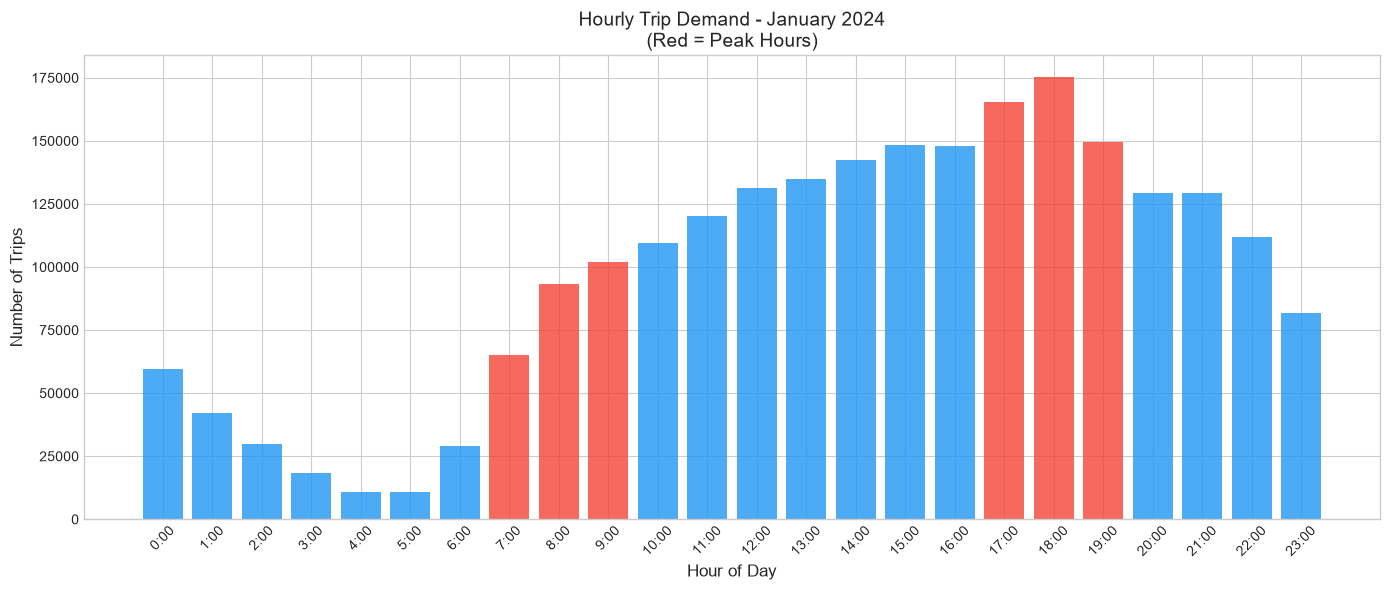

Peak hours: 7-9 AM and 5-7 PM have highest demand


In [3]:
hourly = df.groupby('pickup_hour').size().reset_index(name='trip_count')

fig, ax = plt.subplots(figsize=(14, 6))
colors = ['#F44336' if h in [7,8,9,17,18,19] else '#2196F3' for h in hourly['pickup_hour']]
ax.bar(hourly['pickup_hour'], hourly['trip_count'], color=colors, alpha=0.8)
ax.set_xlabel('Hour of Day', fontsize=12)
ax.set_ylabel('Number of Trips', fontsize=12)
ax.set_title('Hourly Trip Demand - January 2024\n(Red = Peak Hours)', fontsize=14)
ax.set_xticks(range(24))
ax.set_xticklabels([f'{h}:00' for h in range(24)], rotation=45)
plt.tight_layout()
plt.savefig('../visuals/01_hourly_demand.png', dpi=150)
plt.show()
print("Peak hours: 7-9 AM and 5-7 PM have highest demand")

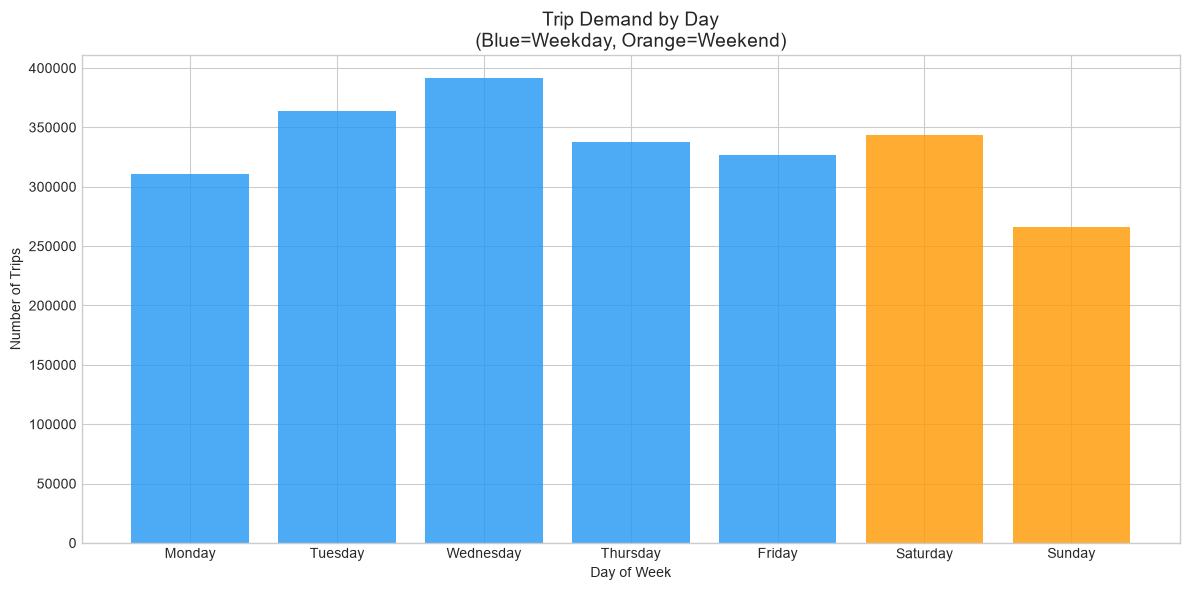

In [4]:
day_demand = df.groupby('pickup_day_name').size().reset_index(name='trips')
day_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
day_demand['pickup_day_name'] = pd.Categorical(day_demand['pickup_day_name'], categories=day_order)
day_demand = day_demand.sort_values('pickup_day_name')

fig, ax = plt.subplots(figsize=(12, 6))
colors = ['#2196F3']*5 + ['#FF9800']*2
ax.bar(day_demand['pickup_day_name'], day_demand['trips'], color=colors, alpha=0.8)
ax.set_xlabel('Day of Week')
ax.set_ylabel('Number of Trips')
ax.set_title('Trip Demand by Day\n(Blue=Weekday, Orange=Weekend)', fontsize=14)
plt.tight_layout()
plt.savefig('../visuals/02_weekday_vs_weekend.png', dpi=150)
plt.show()

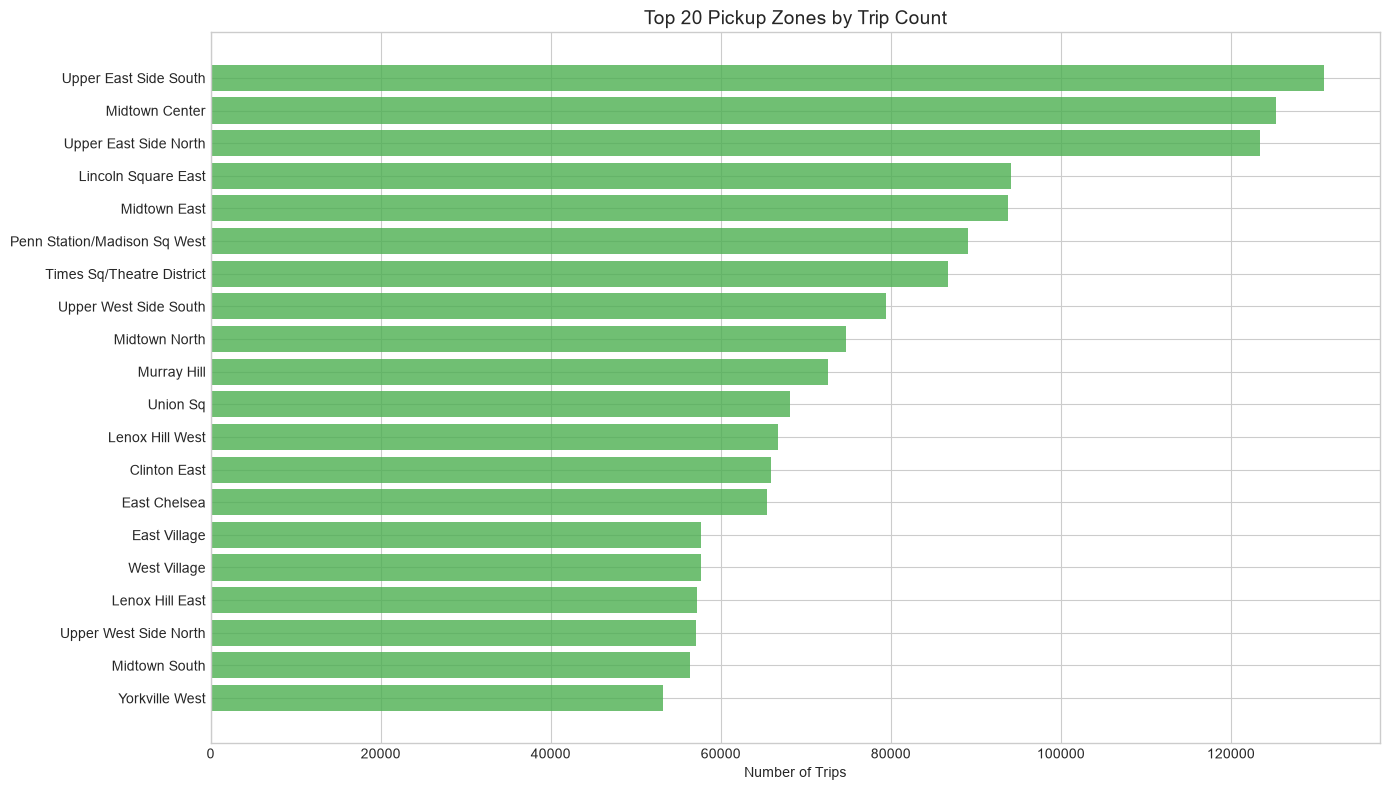

In [5]:
top_zones = df.groupby('PU_zone').size().reset_index(name='trips')
top_zones = top_zones.sort_values('trips', ascending=False).head(20)

fig, ax = plt.subplots(figsize=(14, 8))
ax.barh(top_zones['PU_zone'][::-1], top_zones['trips'][::-1], color='#4CAF50', alpha=0.8)
ax.set_xlabel('Number of Trips')
ax.set_title('Top 20 Pickup Zones by Trip Count', fontsize=14)
plt.tight_layout()
plt.savefig('../visuals/03_top_pickup_zones.png', dpi=150)
plt.show()

Borough Statistics:
               trip_count  avg_speed  avg_duration  pct_congested
PU_borough                                                       
Manhattan         2298525       9.59         11.03           0.61
Queens              28157      18.89         11.42           0.16
Brooklyn             9865      10.94         14.01           0.49
Bronx                1781      10.78         14.49           0.53
Staten Island          19      28.69          4.24           0.16
EWR                     7      19.03          0.92           0.14


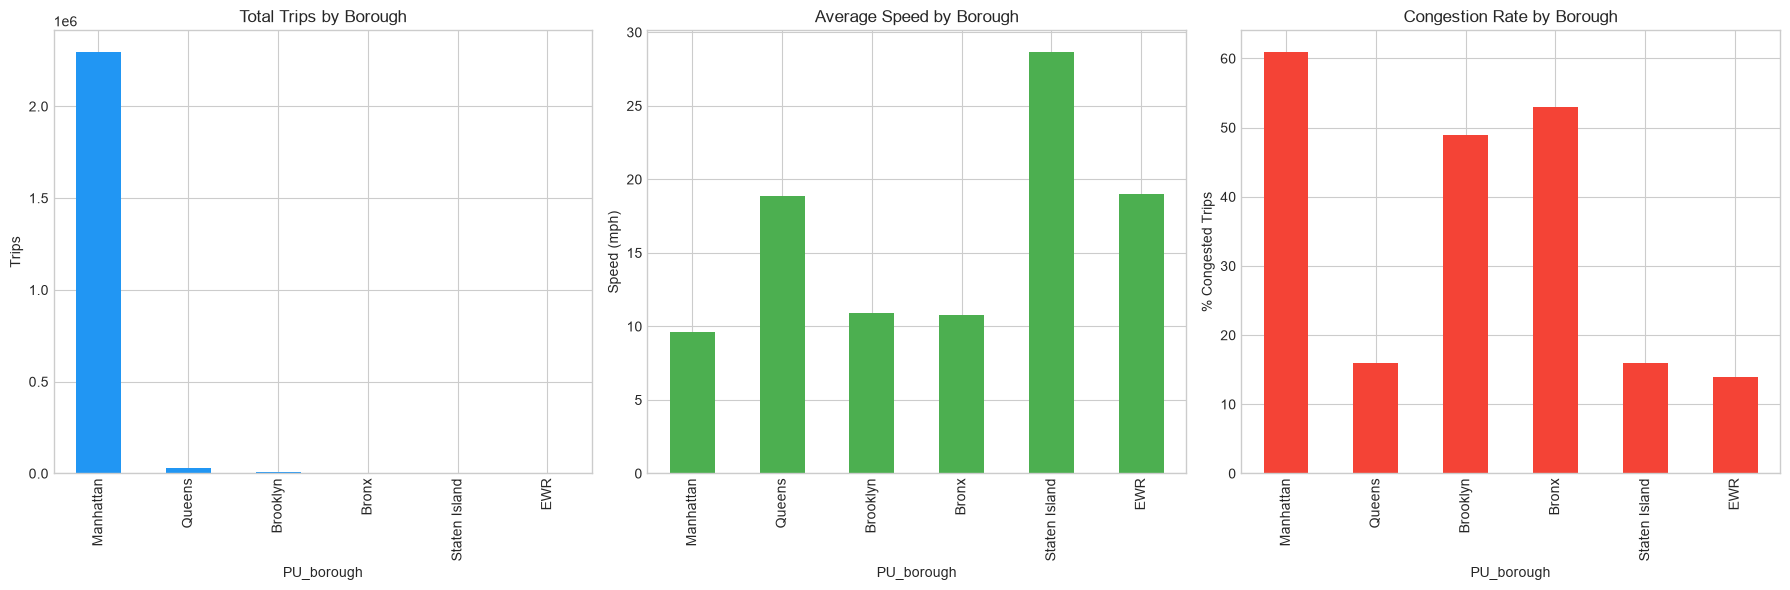

In [6]:
borough_stats = df.groupby('PU_borough').agg(
    trip_count=('trip_distance', 'count'),
    avg_speed=('avg_speed_mph', 'mean'),
    avg_duration=('trip_duration_min', 'mean'),
    pct_congested=('is_congested_trip', 'mean')
).round(2).sort_values('trip_count', ascending=False)

print("Borough Statistics:")
print(borough_stats)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

borough_stats['trip_count'].plot(kind='bar', ax=axes[0], color='#2196F3')
axes[0].set_title('Total Trips by Borough')
axes[0].set_ylabel('Trips')

borough_stats['avg_speed'].plot(kind='bar', ax=axes[1], color='#4CAF50')
axes[1].set_title('Average Speed by Borough')
axes[1].set_ylabel('Speed (mph)')

(borough_stats['pct_congested']*100).plot(kind='bar', ax=axes[2], color='#F44336')
axes[2].set_title('Congestion Rate by Borough')
axes[2].set_ylabel('% Congested Trips')

plt.tight_layout()
plt.savefig('../visuals/04_borough_analysis.png', dpi=150)
plt.show()

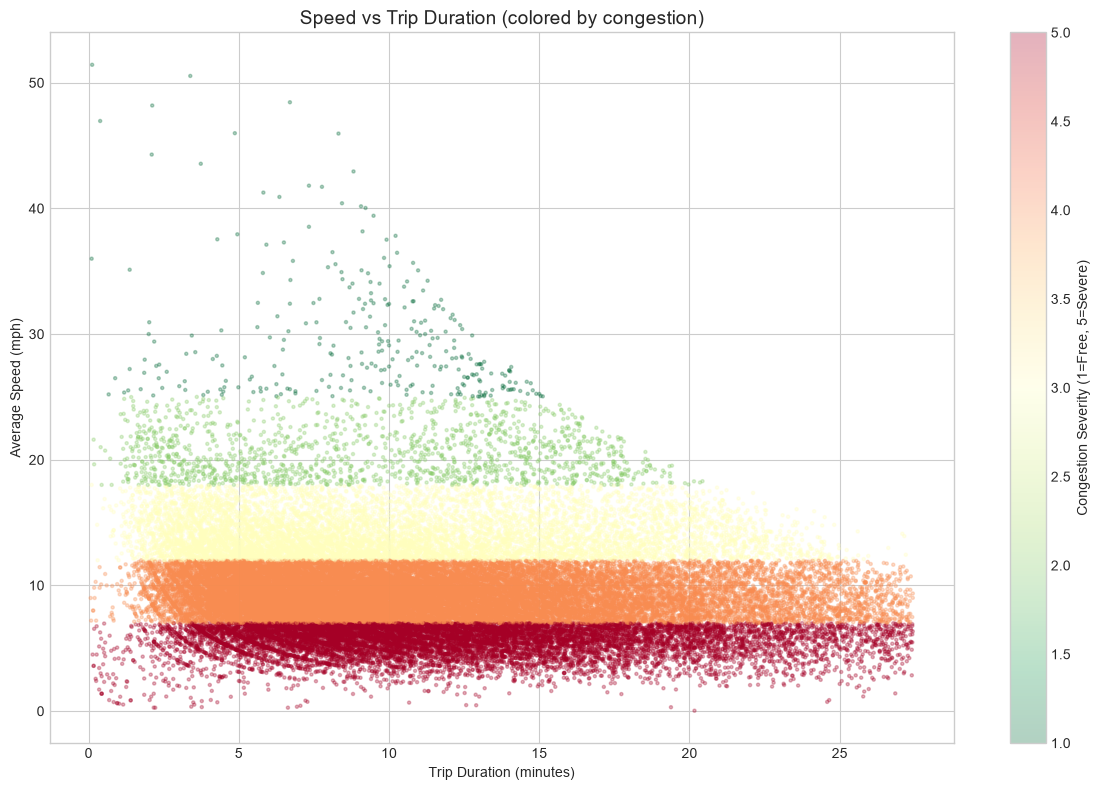

In [7]:
sample = df.dropna(subset=['avg_speed_mph']).sample(n=min(50000, len(df)), random_state=42)

fig, ax = plt.subplots(figsize=(12, 8))
scatter = ax.scatter(
    sample['trip_duration_min'],
    sample['avg_speed_mph'],
    c=sample['congestion_severity'],
    cmap='RdYlGn_r', alpha=0.3, s=5
)
plt.colorbar(scatter, label='Congestion Severity (1=Free, 5=Severe)')
ax.set_xlabel('Trip Duration (minutes)')
ax.set_ylabel('Average Speed (mph)')
ax.set_title('Speed vs Trip Duration (colored by congestion)', fontsize=14)
plt.tight_layout()
plt.savefig('../visuals/05_speed_vs_duration.png', dpi=150)
plt.show()

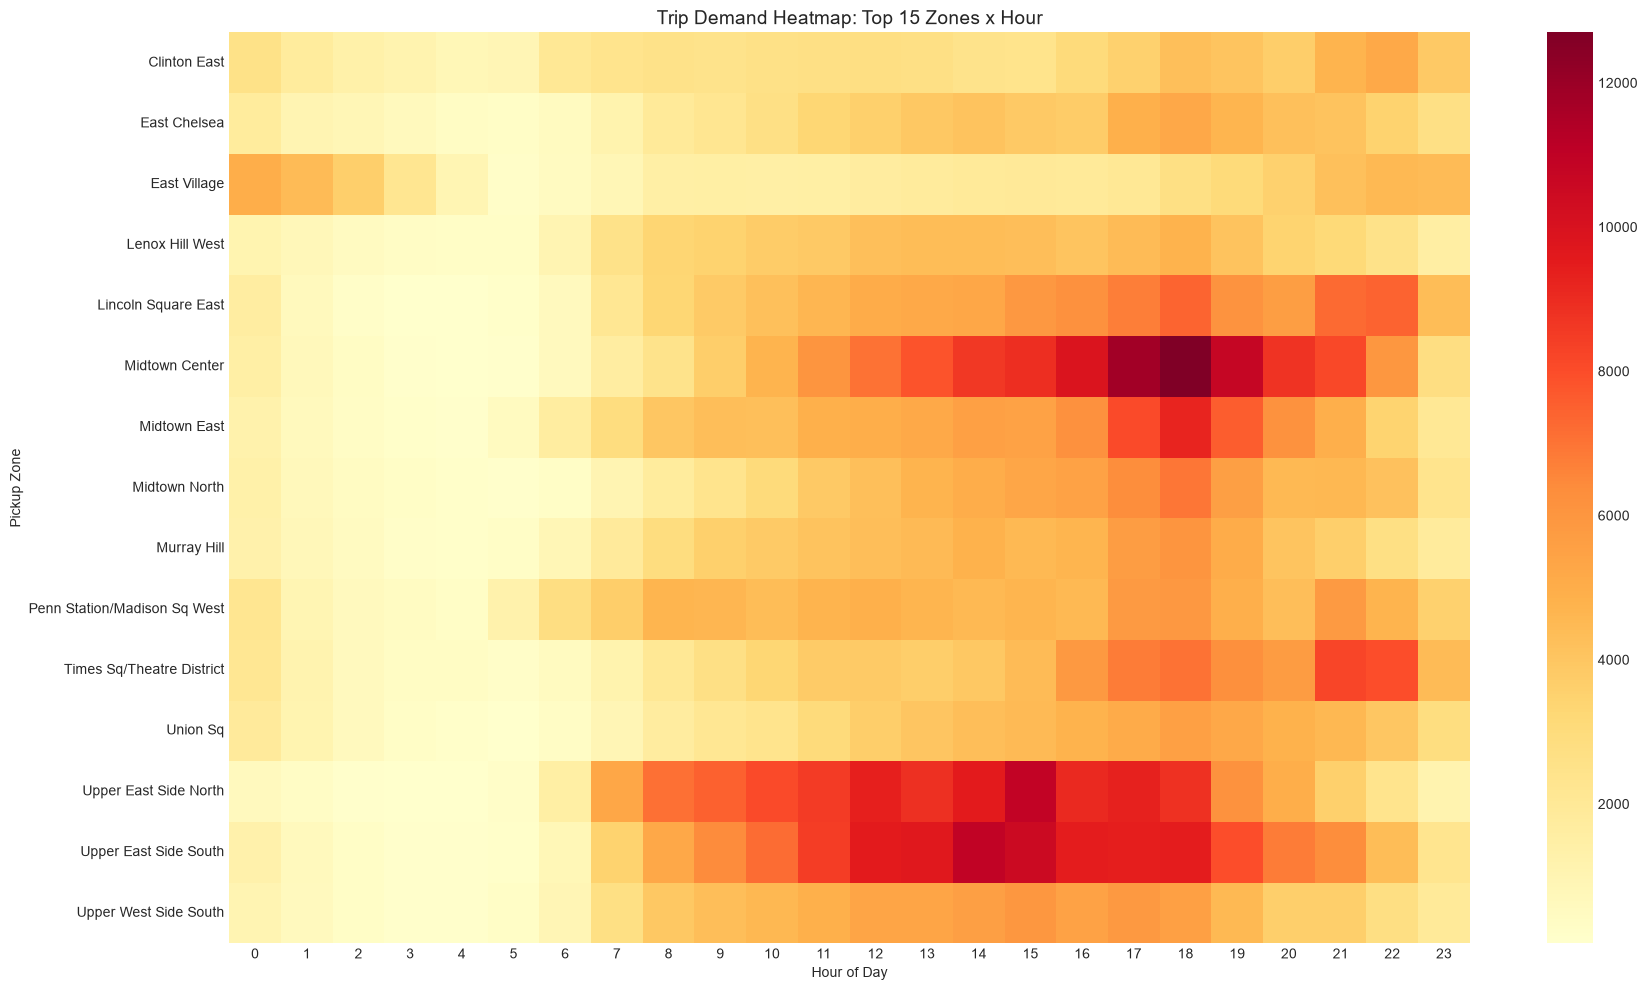

In [8]:
top15_names = top_zones['PU_zone'].head(15).tolist()
heatmap_data = df[df['PU_zone'].isin(top15_names)].pivot_table(
    index='PU_zone', columns='pickup_hour',
    values='trip_distance', aggfunc='count', fill_value=0
)

fig, ax = plt.subplots(figsize=(18, 10))
sns.heatmap(heatmap_data, cmap='YlOrRd', annot=False, fmt='d', ax=ax)
ax.set_title('Trip Demand Heatmap: Top 15 Zones x Hour', fontsize=14)
ax.set_xlabel('Hour of Day')
ax.set_ylabel('Pickup Zone')
plt.tight_layout()
plt.savefig('../visuals/06_zone_hour_heatmap.png', dpi=150)
plt.show()

In [9]:
peak_stats = df.groupby('is_peak').agg(
    avg_speed=('avg_speed_mph', 'mean'),
    avg_duration=('trip_duration_min', 'mean'),
    avg_fare=('fare_amount', 'mean'),
    avg_fare_mile=('fare_per_mile', 'mean'),
    pct_congested=('is_congested_trip', 'mean')
).round(2)

peak_stats.index = ['Off-Peak', 'Peak']
print("Peak vs Off-Peak Comparison:")
print(peak_stats)

speed_drop = (1 - peak_stats.loc['Peak','avg_speed'] / peak_stats.loc['Off-Peak','avg_speed']) * 100
print(f"\nSpeed drops {speed_drop:.1f}% during peak hours!")

Peak vs Off-Peak Comparison:
          avg_speed  avg_duration  avg_fare  avg_fare_mile  pct_congested
Off-Peak       9.85         11.03     12.38           8.24           0.59
Peak           9.40         11.09     12.22           8.41           0.65

Speed drops 4.6% during peak hours!
